# Exercise 7 – Non-Boltzmann sampling (reweighting)

**Week 2 · Monte Carlo sampling**

Samples drawn from the Boltzmann distribution of one potential $V_1$ can be
reused for another potential $V_2$ by giving each sample the weight

$$w_i = e^{-(V_2(x_i) - V_1(x_i))/k_BT}, \qquad
  \langle A\rangle_2 = \frac{\sum_i w_i A(x_i)}{\sum_i w_i}.$$

Here $V_1$ is a soft spring ($k=1$, centred at 0) and $V_2$ a stiff one
($k=10$, centred at 1). The method only works well where the two
distributions overlap.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.montecarlo import boltzmann_pdf, rejection_sample, thermal_average
from comphy.plotting import annotate, setup_axes

rng = np.random.default_rng(0)
kT, lims = 0.15, (-3, 3)
V1 = lambda x: 0.5 * 1 * np.asarray(x) ** 2
V2 = lambda x: 0.5 * 10 * (np.asarray(x) - 1) ** 2
xs = np.linspace(*lims, 600)

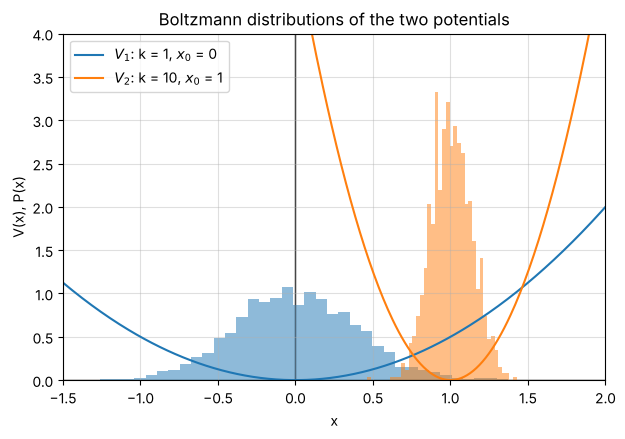

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for V, name, c in [(V1, "$V_1$: k = 1, $x_0$ = 0", "C0"), (V2, "$V_2$: k = 10, $x_0$ = 1", "C1")]:
    sample = rejection_sample(V, kT, lims, 20_000, rng=rng)
    ax.plot(xs, V(xs), color=c, label=name)
    ax.hist(sample, bins=40, density=True, color=c, alpha=0.5)
setup_axes(ax, xlim=(-1.5, 2), ylim=(0, 4), ylabel="V(x), P(x)",
           title="Boltzmann distributions of the two potentials")
ax.legend()
plt.show()

## Reweighting samples from $V_1$ to $V_2$

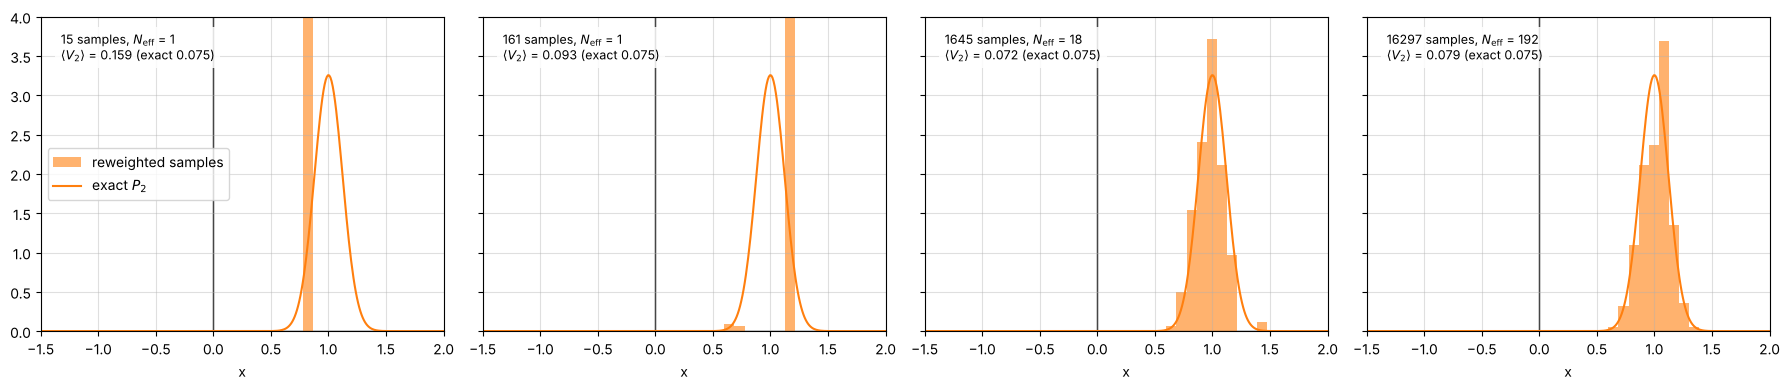

In [3]:
exact = thermal_average(V2, kT, lims)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, n in zip(axes, [100, 1_000, 10_000, 100_000]):
    sample = rejection_sample(V1, kT, lims, n, rng=rng)
    w = np.exp(-(V2(sample) - V1(sample)) / kT)
    estimate = np.sum(w * V2(sample)) / np.sum(w)
    n_eff = w.sum() ** 2 / (w**2).sum()             # effective number of samples
    ax.hist(sample, bins=40, range=(-1.5, 2), density=True, weights=w, color="C1", alpha=0.6,
            label="reweighted samples")
    ax.plot(xs, boltzmann_pdf(V2, kT, lims)(xs), color="C1", label="exact $P_2$")
    annotate(ax, f"{len(sample)} samples, $N_\\mathrm{{eff}}$ = {n_eff:.0f}\n"
                 f"$\\langle V_2\\rangle$ = {estimate:.3f} (exact {exact:.3f})")
    setup_axes(ax, xlim=(-1.5, 2), ylim=(0, 4), ylabel=None)
axes[0].legend(loc="center left")
fig.tight_layout()
plt.show()

Only the few samples from the tail of $P_1$ near $x = 1$ carry significant
weight, so the *effective* number of samples is a small fraction of the
total. With few samples the reweighted estimate is very noisy; with many it
converges to the exact result.